# IDC409: 02 EDA (Cross-market correlation, Model using only stocks data for training)

Upload `stocks_data_clean.csv` to Colab first: click the folder icon on the left, then the upload icon.
Run the cells top to bottom.

## Step 1: Load the data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

STOCK_NAME = "NVDA"

df = pd.read_csv("stocks_data_clean.csv", parse_dates=["date"])
df = df.sort_values("date").set_index("date")

START = "2021-01-01"   # change these two(yyyy/mm/dd)
END   = None   # use None to mean "up to the latest date"
df = df.loc[START:END]

print(df.shape, "|", df.index.min().date(), "to", df.index.max().date())
df.head()

(1515, 8) | 2021-01-05 to 2026-10-30


,stock,gold,oil,usdinr,stock_ret,gold_ret,oil_ret,usdinr_ret
date,,,,,,,,
2021-01-05,13.335953,1954.400024,49.930000,73.320000,0.022210,0.004007,0.048509,0.003119
2021-01-06,12.549760,1908.599976,50.630001,73.374802,-0.058953,-0.023434,0.014020,0.000747
2021-01-07,13.275516,1913.599976,50.830002,73.360001,0.057830,0.002620,0.003950,-0.000202
2021-01-08,13.208611,1835.400024,52.240002,73.445999,-0.005040,-0.040865,0.027740,0.001172
2021-01-11,13.551593,1850.800049,52.250000,73.373398,0.025967,0.008391,0.000191,-0.000988


## Step 2: Normalised price comparison
Every asset is divided by its first-day price, so all lines start at 1. This lets you compare assets
with completely different price scales (rupees, dollars, index levels) on one chart.

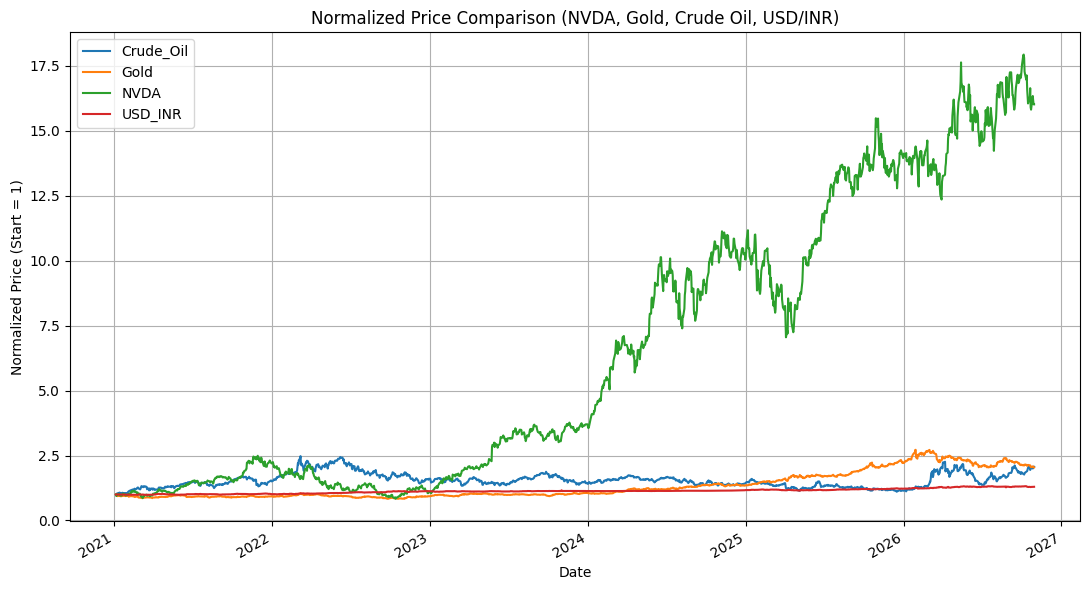

In [2]:
labels = {"oil": "Crude_Oil", "gold": "Gold", "stock": STOCK_NAME, "usdinr": "USD_INR"}

prices = df[list(labels.keys())].rename(columns=labels)
normalized = prices / prices.iloc[0]

ax = normalized.plot(figsize=(11, 6), grid=True)
ax.set_title(f"Normalized Price Comparison ({STOCK_NAME}, Gold, Crude Oil, USD/INR)")
ax.set_xlabel("Date")
ax.set_ylabel("Normalized Price (Start = 1)")
plt.tight_layout()
plt.savefig("normalized_prices.png", dpi=150)
plt.show()

## Step 3: Correlation of daily returns
We correlate **returns** (daily % change), not raw prices. Raw prices trend over time, which creates
fake correlations (two things that both rise look related even if they are not).

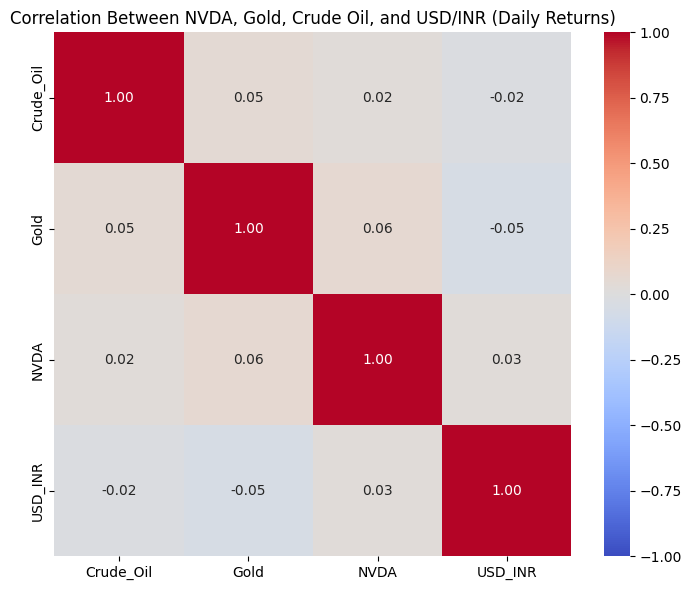

In [3]:
ret_labels = {"oil_ret": "Crude_Oil", "gold_ret": "Gold", "stock_ret": STOCK_NAME, "usdinr_ret": "USD_INR"}

returns = df[list(ret_labels.keys())].rename(columns=ret_labels)
corr = returns.corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title(f"Correlation Between {STOCK_NAME}, Gold, Crude Oil, and USD/INR (Daily Returns)")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=150)
plt.show()

Download the full NVDA data

In [4]:
import yfinance as yf

TICKER = "NVDA"
START = "2021-01-01"
END = None            # None = latest date, or e.g. "2025-12-31"

ohlc = yf.download(TICKER, start=START, end=END, auto_adjust=True, progress=False)
if isinstance(ohlc.columns, pd.MultiIndex):
    ohlc.columns = ohlc.columns.droplevel(1)
ohlc.index = pd.to_datetime(ohlc.index).tz_localize(None)
ohlc = ohlc.dropna()

Price-to-moving-average ratio and volatility features

In [5]:
close = ohlc["Close"]
volume = ohlc["Volume"]

feat = pd.DataFrame(index=ohlc.index)
feat["daily_return"] = close.pct_change()
feat["log_return"] = np.log(close / close.shift(1))

for w in (3, 5, 10):
    feat[f"volatility_{w}d"] = feat["daily_return"].rolling(w).std()

feat["volume_change"] = volume.pct_change()
feat["volume_ma_5d"] = volume.rolling(5).mean()
feat["price_ma_5d"] = close.rolling(5).mean()
feat["price_ma_10d"] = close.rolling(10).mean()
feat["price_ma_ratio"] = feat["price_ma_5d"] / feat["price_ma_10d"]

feat = feat.dropna()
print(feat.shape)
feat.head()

(1453, 10)


,daily_return,log_return,volatility_3d,volatility_5d,volatility_10d,volume_change,volume_ma_5d,price_ma_5d,price_ma_10d,price_ma_ratio
Date,,,,,,,,,,
2021-01-19,0.012889,0.012807,0.021975,0.017021,0.032588,-0.185730,257718400.0,13.152448,13.168367,0.998791
2021-01-20,0.026141,0.025806,0.026997,0.023000,0.032911,0.143173,251137600.0,13.128771,13.164487,0.997287
2021-01-21,0.037540,0.036853,0.012337,0.029101,0.027310,0.306329,276688000.0,13.195576,13.289144,0.992959
2021-01-22,-0.011177,-0.011240,0.025482,0.026157,0.022051,-0.269288,269428000.0,13.297500,13.325805,0.997876
2021-01-25,-0.004321,-0.004330,0.026372,0.020349,0.022023,0.017389,264094400.0,13.455436,13.363261,1.006898


Summary statistics

In [6]:
close = ohlc["Close"]
daily_ret = close.pct_change().dropna()
n = len(daily_ret)

up_days = int((daily_ret > 0).sum())
down_flat_days = int((daily_ret <= 0).sum())
variation = (close.max() - close.min()) / close.min()

print(f"Up days (price increased): {up_days} ({up_days / n:.1%})")
print(f"Down/flat days: {down_flat_days} ({down_flat_days / n:.1%})")
print(f"Average closing price: ${close.mean():,.2f}")
print(f"Volatility (daily std of returns): {daily_ret.std():.2%}")
print(f"Max daily gain: {daily_ret.max():+.2%}")
print(f"Max daily loss: {daily_ret.min():+.2%}")
print(f"Variation across the period: {variation:.0%}")

Up days (price increased): 778 (53.2%)
Down/flat days: 684 (46.8%)
Average closing price: $86.41
Volatility (daily std of returns): 3.17%
Max daily gain: +24.37%
Max daily loss: -16.97%
Variation across the period: 2039%


The chart

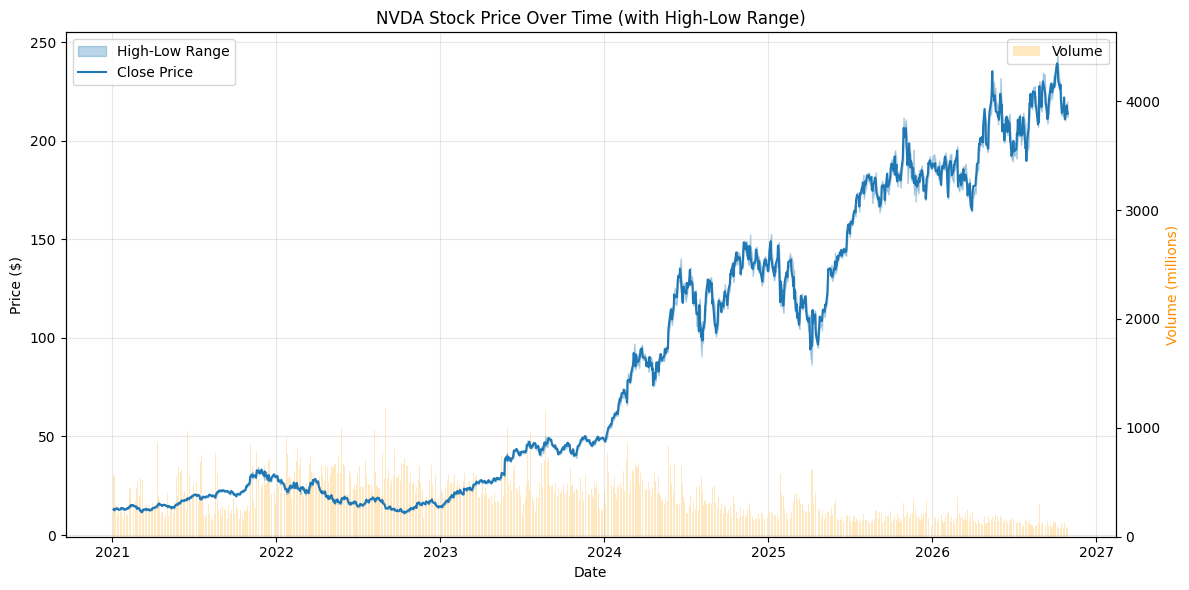

In [7]:
fig, ax = plt.subplots(figsize=(12, 6))
ax2 = ax.twinx()

vol_m = ohlc["Volume"] / 1e6
ax2.bar(ohlc.index, vol_m, color="orange", alpha=0.25, width=1.0, label="Volume")
ax2.set_ylabel("Volume (millions)", color="darkorange")
ax2.set_ylim(0, vol_m.max() * 3)

ax.fill_between(ohlc.index, ohlc["Low"], ohlc["High"], color="tab:blue", alpha=0.3, label="High-Low Range")
ax.plot(ohlc.index, close, color="tab:blue", linewidth=1.5, label="Close Price")
ax.set_ylabel("Price ($)")
ax.set_xlabel("Date")
ax.set_title(f"{TICKER} Stock Price Over Time (with High-Low Range)")
ax.grid(True, alpha=0.3)

ax.set_zorder(ax2.get_zorder() + 1)   # price line drawn on top of the bars
ax.patch.set_visible(False)
ax.legend(loc="upper left")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.savefig("price_volume_chart.png", dpi=150)
plt.show()

Target and time-based split

In [8]:
data = feat.copy()
data["target_return"] = data["daily_return"].shift(-1)   # tomorrow's return
data = data.dropna()                                      # last row has no "tomorrow"

features = ["daily_return", "log_return", "volatility_3d", "volatility_5d", "volatility_10d",
            "volume_change", "volume_ma_5d", "price_ma_5d", "price_ma_10d", "price_ma_ratio"]

split = int(len(data) * 0.8)                              # first 80% train, last 20% test
train, test = data.iloc[:split], data.iloc[split:]

X_train, y_train = train[features], train["target_return"]
X_test, y_test = test[features], test["target_return"]
print("Train:", len(train), "| Test:", len(test))

Train: 1161 | Test: 291


Random forest regressor

In [9]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

rf = RandomForestRegressor(n_estimators=300, max_depth=5, min_samples_leaf=10,
                           random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)

print("Random Forest")
print(f"  MAE : {mean_absolute_error(y_test, pred):.4f}")
print(f"  RMSE: {np.sqrt(mean_squared_error(y_test, pred)):.4f}")
print(f"  R²  : {r2_score(y_test, pred):.4f}")

base = test["daily_return"]                               # baseline: tomorrow = today
print("Baseline (tomorrow = today)")
print(f"  MAE : {mean_absolute_error(y_test, base):.4f}")
print(f"  RMSE: {np.sqrt(mean_squared_error(y_test, base)):.4f}")

Random Forest
  MAE : 0.0181
  RMSE: 0.0231
  R²  : 0.0080
Baseline (tomorrow = today)
  MAE : 0.0260
  RMSE: 0.0339


Confusion matrix

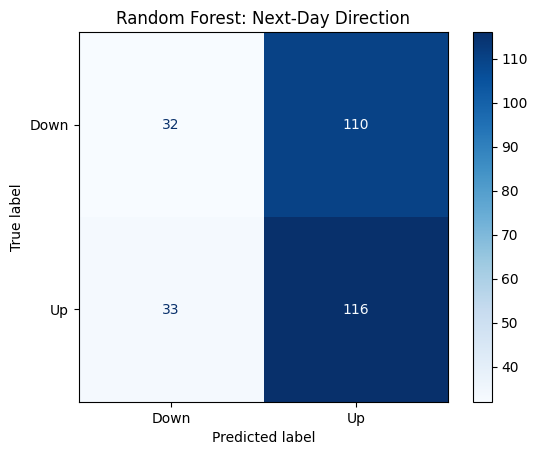

Model    accuracy: 0.509 | F1: 0.619
Baseline accuracy: 0.512 | F1: 0.523
Always-Up accuracy: 0.512


In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score

y_true_dir = (y_test > 0).astype(int)    # 1 = Up, 0 = Down/flat
y_pred_dir = (pred > 0).astype(int)

cm = confusion_matrix(y_true_dir, y_pred_dir)
ConfusionMatrixDisplay(cm, display_labels=["Down", "Up"]).plot(cmap="Blues")
plt.title("Random Forest: Next-Day Direction")
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

print("Model    accuracy:", round(accuracy_score(y_true_dir, y_pred_dir), 3),
      "| F1:", round(f1_score(y_true_dir, y_pred_dir), 3))

base_dir = (test["daily_return"] > 0).astype(int)         # baseline: tomorrow's direction = today's
print("Baseline accuracy:", round(accuracy_score(y_true_dir, base_dir), 3),
      "| F1:", round(f1_score(y_true_dir, base_dir), 3))
print("Always-Up accuracy:", round(y_true_dir.mean(), 3))

Which features mattered

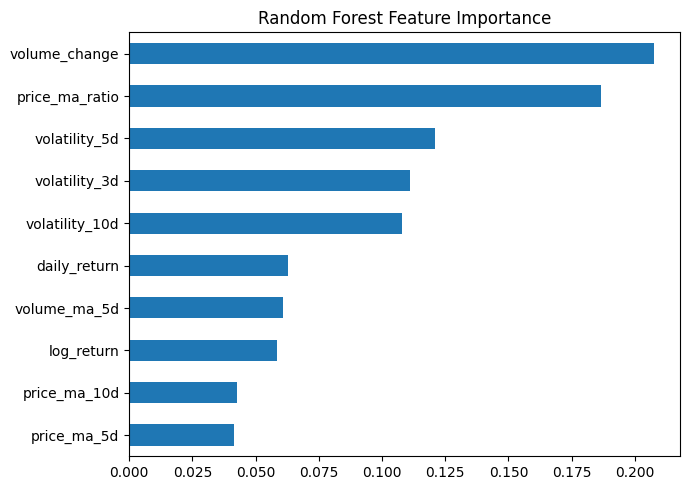

In [11]:
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot.barh(figsize=(7, 5), title="Random Forest Feature Importance")
plt.tight_layout()
plt.show()

Actual vs predicted returns over time

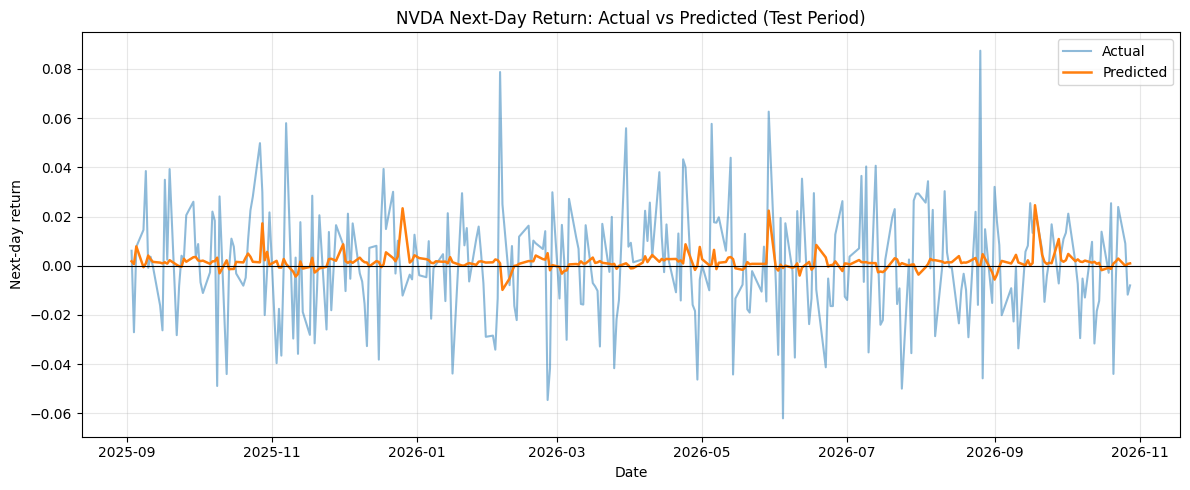

In [12]:
pred_s = pd.Series(pred, index=test.index)

plt.figure(figsize=(12, 5))
plt.plot(y_test.index, y_test, label="Actual", alpha=0.5)
plt.plot(pred_s.index, pred_s, label="Predicted", linewidth=1.8)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("NVDA Next-Day Return: Actual vs Predicted (Test Period)")
plt.xlabel("Date")
plt.ylabel("Next-day return")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("rf_actual_vs_predicted.png", dpi=150)
plt.show()

Scatter of actual vs predicted

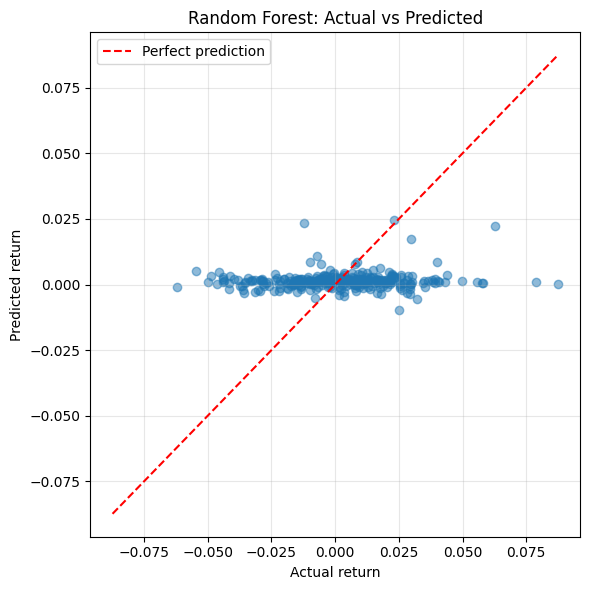

In [13]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.5)
lim = max(abs(y_test).max(), abs(pred).max())
plt.plot([-lim, lim], [-lim, lim], "r--", label="Perfect prediction")
plt.xlabel("Actual return")
plt.ylabel("Predicted return")
plt.title("Random Forest: Actual vs Predicted")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("rf_scatter.png", dpi=150)
plt.show()

Predicted direction on the price chart

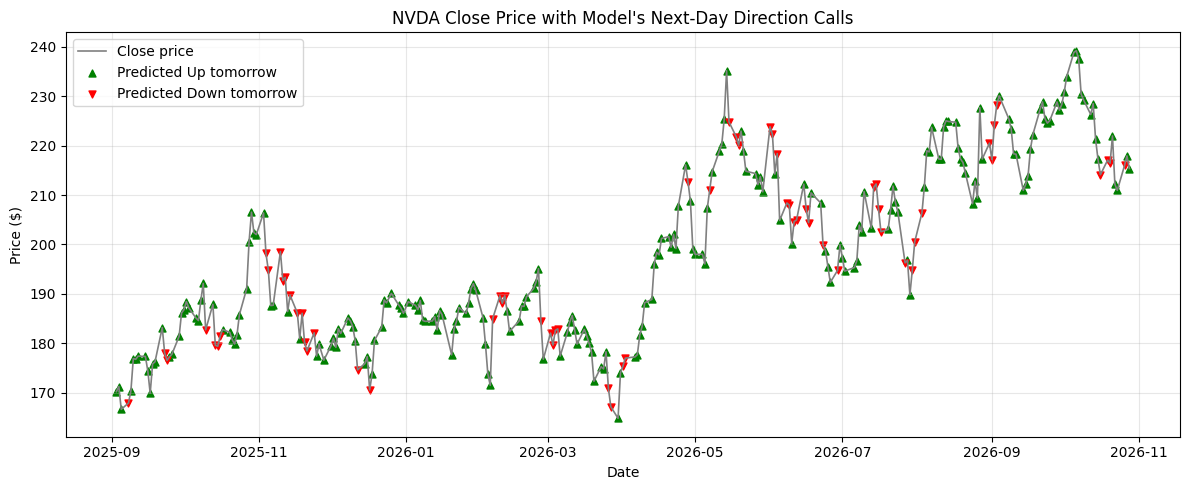

In [14]:
test_close = close.loc[test.index]
up = pred_s > 0

plt.figure(figsize=(12, 5))
plt.plot(test_close.index, test_close, color="gray", linewidth=1.2, label="Close price")
plt.scatter(test_close.index[up], test_close[up], marker="^", color="green", s=25, label="Predicted Up tomorrow")
plt.scatter(test_close.index[~up], test_close[~up], marker="v", color="red", s=25, label="Predicted Down tomorrow")
plt.title("NVDA Close Price with Model's Next-Day Direction Calls")
plt.xlabel("Date")
plt.ylabel("Price ($)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("rf_direction_on_price.png", dpi=150)
plt.show()

One tree from the forest

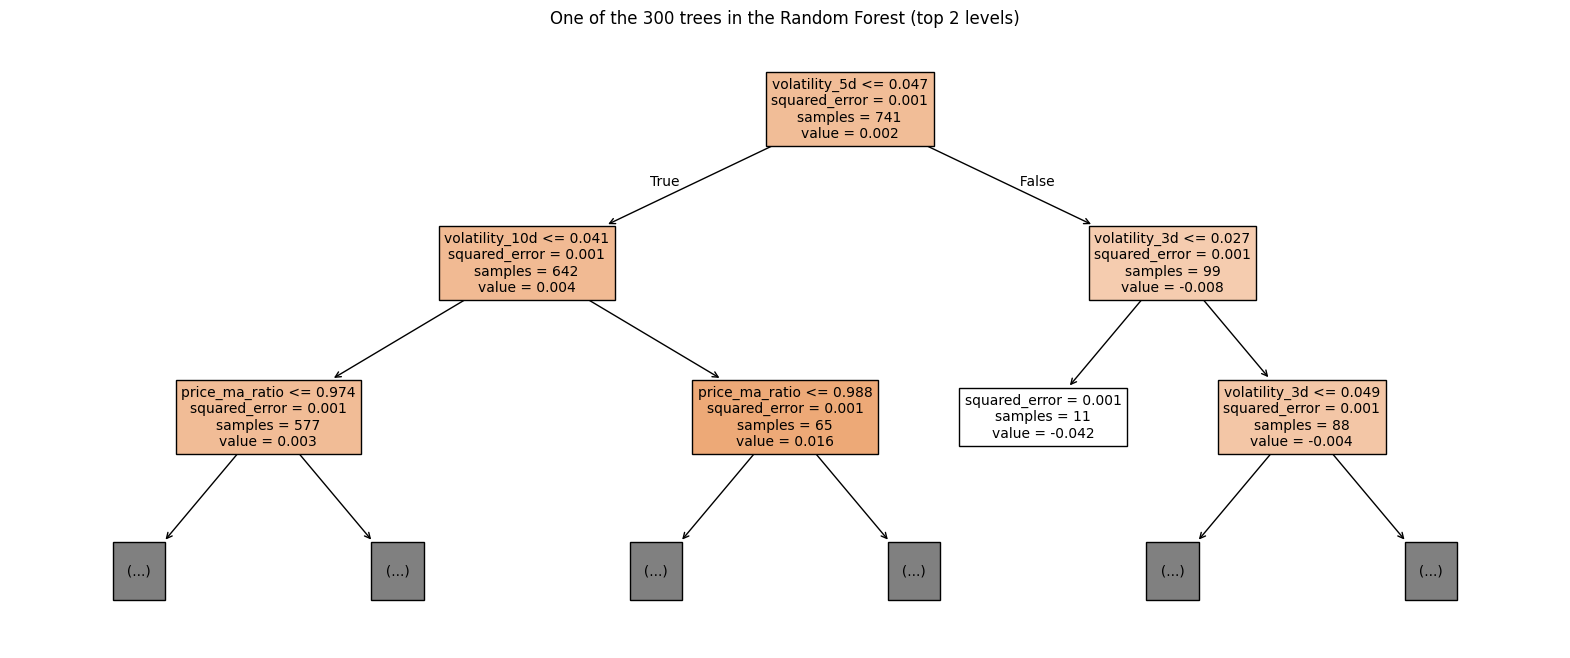

In [15]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 8))
plot_tree(rf.estimators_[0], feature_names=features, max_depth=2, filled=True, fontsize=10)
plt.title("One of the 300 trees in the Random Forest (top 2 levels)")
plt.savefig("rf_single_tree.png", dpi=150)
plt.show()